# 01 – Variety: dữ liệu đa dạng & định dạng Parquet

**Variety** (tính đa dạng) là chữ V thứ ba của Big Data: dữ liệu không chỉ nhiều (Volume), đến nhanh (Velocity) mà còn **khác nhau về cấu trúc và kiểu**. Notebook này chứng minh Variety trên dataset FIFA bằng 3 phần:

1. **Nhiều loại thực thể với cấu trúc khác nhau:** cầu thủ, đội bóng, HLV, ở cả 2 giới, liên kết với nhau bằng khoá.
2. **Trường bán cấu trúc (semi-structured):** một ô CSV chứa *danh sách* (`"CM, CAM"`), chỉ số dạng `"89+3"`, URL ảnh. Ta biến chúng thành kiểu mảng (`array<string>`).
3. **Lưu cùng một dữ liệu bằng 2 định dạng, CSV (theo hàng) và Parquet (theo cột)**, rồi so sánh dung lượng và tốc độ truy vấn.

> **Parquet là gì?** Parquet là định dạng file **lưu theo cột** (columnar) của hệ sinh thái Hadoop, do Twitter và Cloudera phát triển, nay thuộc Apache. CSV lưu từng *dòng* nối tiếp nhau. Parquet gom tất cả giá trị của *một cột* lại cạnh nhau. Nhờ vậy:
> - **Chỉ đọc cột cần dùng** (column pruning): hỏi `overall` thì không phải đọc 109 cột còn lại.
> - **Nén tốt hơn rất nhiều**: các giá trị cùng cột giống nhau (ví dụ cột `fifa_version` toàn số 15…23) nên nén rất hiệu quả.
> - **Có sẵn schema và kiểu dữ liệu** (int, date, array…), không phải đoán kiểu lại mỗi lần đọc như CSV.
> - **Bỏ qua cả khối dữ liệu không thoả điều kiện lọc** (predicate pushdown), vì mỗi khối lưu sẵn min/max.
> - **Lưu được kiểu lồng nhau** (mảng, struct), là thứ CSV không làm được.

Chạy lần lượt từng ô bằng **Shift+Enter**. Cả notebook mất khoảng **15–30 phút**, vì phải đọc file CSV 5,6 GB vài lần. Kết quả (bảng CSV và ảnh) được lưu vào `notebooks/results/`.

In [32]:
import os, time
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F, types as T

BASE    = os.environ.get("FIFA_BASE", "hdfs://namenode:8020")
RAW     = f"{BASE}/fifa/raw"
CURATED = f"{BASE}/fifa/curated"
RESULTS = os.environ.get("FIFA_RESULTS", "/home/jovyan/work/results")   # = D:\Big Data\notebooks\results
os.makedirs(RESULTS, exist_ok=True)

builder = (SparkSession.builder.appName("01-variety-parquet")
           .config("spark.driver.memory", "3g")
           .config("spark.sql.shuffle.partitions", "16")
           .config("spark.sql.parquet.writeLegacyFormat", "true"))
if BASE.startswith("hdfs://"):
    builder = builder.config("spark.hadoop.fs.defaultFS", BASE)
spark = builder.getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

# Tien ich: dung luong tren HDFS va do thoi gian
hconf = spark._jsc.hadoopConfiguration()
def hpath(p):
    return spark._jvm.org.apache.hadoop.fs.Path(p)
def du(p):
    path = hpath(p)
    cs = path.getFileSystem(hconf).getContentSummary(path)
    return {"bytes": cs.getLength(), "bytes_tren_dia": cs.getSpaceConsumed(), "so_file": cs.getFileCount()}
def timed(fn):
    t = time.perf_counter(); r = fn(); return r, time.perf_counter() - t
MB = 1024 * 1024
print("Spark", spark.version, "| doc du lieu tu", RAW)

Spark 3.5.0 | doc du lieu tu hdfs://namenode:8020/fifa/raw


## Phần 1 – Ba loại thực thể, ba cấu trúc khác nhau

Đọc cả thư mục `players/` (gồm 2 thư mục con `gender=male` và `gender=female`). Spark **tự sinh cột `gender`** từ tên thư mục, đúng như cách mình chia thư mục ở bước đưa dữ liệu lên HDFS.

Ô dưới đây đọc lướt cả file 5,6 GB để đoán kiểu dữ liệu từng cột (`inferSchema`), mất khoảng **1–3 phút**.

In [33]:
csv_opts = dict(header=True, inferSchema=True, escape='"')
(players, t_inf) = timed(lambda: spark.read.options(**csv_opts, samplingRatio=0.02).csv(f"{RAW}/players"))
teams   = spark.read.options(**csv_opts).csv(f"{RAW}/teams")
coaches = spark.read.options(**csv_opts).csv(f"{RAW}/coaches")
print(f"Đoán kiểu dữ liệu cầu thủ mất {t_inf:.1f} giây")

def nhom_kieu(dt):
    if isinstance(dt, (T.IntegerType, T.LongType, T.ShortType)): return "số nguyên"
    if isinstance(dt, (T.DoubleType, T.FloatType, T.DecimalType)): return "số thực"
    if isinstance(dt, (T.DateType, T.TimestampType, T.TimestampNTZType)): return "ngày giờ"
    return "chuỗi"

rows = []
for ten, df in [("players", players), ("teams", teams), ("coaches", coaches)]:
    dem = pd.Series([nhom_kieu(f.dataType) for f in df.schema]).value_counts()
    rows.append({"thực_thể": ten, "số cột": len(df.columns),
                 **{k: int(dem.get(k, 0)) for k in ["số nguyên", "số thực", "chuỗi", "ngày giờ"]},
                 "số dòng": teams.count() if ten == "teams" else (coaches.count() if ten == "coaches" else None)})
entity_summary = pd.DataFrame(rows)
entity_summary  # so_dong cua players se dem o Phan 3 (doc tu Parquet cho nhanh)

Đoán kiểu dữ liệu cầu thủ mất 6.4 giây


,thực_thể,số cột,số nguyên,số thực,chuỗi,ngày giờ,số dòng
0,players,111,63,0,45,3,NaN
1,teams,55,39,2,13,1,392996.0
2,coaches,9,2,0,6,1,1207.0


In [34]:
# Cac thuc the lien ket voi nhau bang khoa, giong mot CSDL quan he
print("players.club_team_id  ->  teams.team_id")
print("teams.coach_id        ->  coaches.coach_id")
print("Cột chung players & teams:", sorted(set(players.columns) & set(teams.columns)))
print("Cột chỉ có ở coaches     :", sorted(set(coaches.columns) - set(players.columns) - set(teams.columns)))

players.club_team_id  ->  teams.team_id
teams.coach_id        ->  coaches.coach_id
Cột chung players & teams: ['fifa_update', 'fifa_update_date', 'fifa_version', 'gender', 'league_id', 'league_level', 'league_name', 'nationality_id', 'nationality_name', 'overall']
Cột chỉ có ở coaches     : ['coach_url', 'face_url']


## Phần 2 – Trường bán cấu trúc nằm trong CSV

Nhìn bề ngoài thì CSV là bảng phẳng, nhưng nhiều ô thật ra chứa **dữ liệu có cấu trúc bên trong**:

| Cột | Ví dụ | Bản chất |
|---|---|---|
| `player_positions` | `"CM, CAM"` | danh sách vị trí |
| `player_traits` | `"Injury Prone, Playmaker (AI)"` | danh sách đặc điểm |
| `player_tags` | `"#Speedster, #Dribbler"` | danh sách nhãn |
| `ls`, `st`, `cam`… | `"89+3"` | chỉ số gốc + điểm cộng |
| `player_face_url` | `https://cdn.sofifa.net/...png` | tham chiếu tới **ảnh** (dữ liệu phi cấu trúc) |

In [35]:
players.select("short_name", "fifa_version", "player_positions", "player_traits",
               "player_tags", "ls", "player_face_url").where("player_traits IS NOT NULL").show(5, truncate=45)

+--------------+------------+----------------+---------------------------------------------+---------------------------------------------+----+---------------------------------------------+
|    short_name|fifa_version|player_positions|                                player_traits|                                  player_tags|  ls|                              player_face_url|
+--------------+------------+----------------+---------------------------------------------+---------------------------------------------+----+---------------------------------------------+
|      L. Messi|          23|              RW|Finesse Shot, Long Shot Taker (AI), Playma...|#Dribbler, #Distance Shooter, #FK Speciali...|87+3|https://cdn.sofifa.net/players/158/023/23_...|
|    K. Benzema|          23|          CF, ST|Leadership, Finesse Shot, Playmaker (AI), ...|                 #Poacher, #Clinical Finisher|89+2|https://cdn.sofifa.net/players/165/153/23_...|
|R. Lewandowski|          23|              ST|Soli

In [36]:
# Bien chuoi thanh kieu mang (array<string>) va tach "89+3" thanh so nguyen
def tach_list(c):
    return F.when(F.col(c).isNull(), None).otherwise(F.split(F.regexp_replace(F.col(c), r"\s*,\s*", ","), ","))

players_rich = (players
    .withColumn("positions_arr", tach_list("player_positions"))
    .withColumn("traits_arr",    tach_list("player_traits"))
    .withColumn("tags_arr",      tach_list("player_tags"))
    .withColumn("st_base", F.regexp_extract("st", r"^(\d+)", 1).cast("int")))

players_rich.select("short_name", "positions_arr", "traits_arr", "st", "st_base").where("traits_arr IS NOT NULL").show(5, truncate=50)
players_rich.select("positions_arr", "traits_arr", "tags_arr").printSchema()

+--------------+-------------+--------------------------------------------------+----+-------+
|    short_name|positions_arr|                                        traits_arr|  st|st_base|
+--------------+-------------+--------------------------------------------------+----+-------+
|      L. Messi|         [RW]|[Finesse Shot, Long Shot Taker (AI), Playmaker ...|87+3|     87|
|    K. Benzema|     [CF, ST]|[Leadership, Finesse Shot, Playmaker (AI), Outs...|89+2|     89|
|R. Lewandowski|         [ST]|[Solid Player, Finesse Shot, Outside Foot Shot,...|89+2|     89|
|  K. De Bruyne|    [CM, CAM]|[Injury Prone, Leadership, Early Crosser, Long ...|83+3|     83|
|     K. Mbappé|     [ST, LW]|[Solid Player, Flair, Speed Dribbler (AI), Outs...|89+3|     89|
+--------------+-------------+--------------------------------------------------+----+-------+
only showing top 5 rows

root
 |-- positions_arr: array (nullable = true)
 |    |-- element: string (containsNull = false)
 |-- traits_arr: array

## Phần 3 – Chuyển sang Parquet và so sánh dung lượng

Ghi toàn bộ cầu thủ ra `/fifa/curated/players_parquet`, **phân vùng theo `gender` và `fifa_version`**. Mỗi phiên bản FIFA nằm trong một thư mục riêng. Khi truy vấn chỉ hỏi FIFA 23, Spark sẽ **bỏ qua hẳn** các thư mục 15…22 (partition pruning).

Bước này đọc toàn bộ 5,6 GB và ghi ra Parquet, mất khoảng **3–10 phút**. Mở http://localhost:4040 để xem tiến độ job.

In [37]:
PQ_PLAYERS = f"{CURATED}/players_parquet"
_, t_write = timed(lambda: players_rich.write.mode("overwrite")
                   .partitionBy("gender", "fifa_version").parquet(PQ_PLAYERS))
teams.write.mode("overwrite").partitionBy("gender").parquet(f"{CURATED}/teams_parquet")
coaches.write.mode("overwrite").partitionBy("gender").parquet(f"{CURATED}/coaches_parquet")
print(f"Chuyển CSV -> Parquet mất {t_write/60:.1f} phút")

pq_players = spark.read.parquet(PQ_PLAYERS)
n_players = pq_players.count()
entity_summary.loc[entity_summary.thực_thể == "players", "số dòng"] = n_players
entity_summary.to_csv(f"{RESULTS}/variety_entities.csv", index=False)
print(f"Tổng số bàn ghi cầu thủ: {n_players:,}")
entity_summary

Chuyển CSV -> Parquet mất 1.9 phút
Tổng số bàn ghi cầu thủ: 10,184,951


,thực_thể,số cột,số nguyên,số thực,chuỗi,ngày giờ,số dòng
0,players,111,63,0,45,3,10184951.0
1,teams,55,39,2,13,1,392996.0
2,coaches,9,2,0,6,1,1207.0


In [38]:
# So sanh dung luong (bytes_tren_dia = da tinh ca 3 ban sao cua HDFS)
size_rows = []
for nhan, p in [("CSV - cầu thủ nam",     f"{RAW}/players/gender=male"),
                ("Parquet - cầu thủ nam", f"{PQ_PLAYERS}/gender=male"),
                ("CSV - ALL",          f"{RAW}"),
                ("Parquet - ALL",      f"{CURATED}")]:
    d = du(p)
    size_rows.append({"định dạng": nhan, "MB": round(d["bytes"] / MB, 1),
                      "MB_tren_dia_x3": round(d["bytes_tren_dia"] / MB, 1), "số_file": d["so_file"]})
sizes = pd.DataFrame(size_rows)
ratio = sizes.MB[0] / sizes.MB[1]
sizes.to_csv(f"{RESULTS}/variety_size.csv", index=False)
print(f"Parquet nhỏ hơn CSV {ratio:.1f} lan (cầu thủ nam)")
sizes

Parquet nhỏ hơn CSV 4.5 lan (cầu thủ nam)


,định dạng,MB,MB_tren_dia_x3,số_file
0,CSV - cầu thủ nam,5376.0,16127.9,1
1,Parquet - cầu thủ nam,1202.6,3607.8,50
2,CSV - ALL,5575.6,16726.7,6
3,Parquet - ALL,1225.9,3677.6,70


## Phần 4 – Cùng một câu hỏi, đọc từ CSV và từ Parquet

Cả hai đều chỉ dùng dữ liệu **cầu thủ nam**. CSV được đọc với schema có sẵn (không đoán kiểu lại), để so sánh công bằng.

| Câu hỏi | Parquet có lợi thế gì |
|---|---|
| Q1. Đếm số bản ghi | Đọc số dòng có sẵn trong phần metadata của file |
| Q2. Overall trung bình theo phiên bản | Chỉ đọc 2 cột trên 110 |
| Q3. Cầu thủ FIFA 23 có overall ≥ 85 | Bỏ qua 8 thư mục phiên bản khác, lọc ngay khi đọc |
| Q4. Giá trị lớn nhất của **mọi** cột số | Gần như không có, vì phải đọc hết các cột. Đây là câu đối chứng |

Mất khoảng **5–15 phút**, chủ yếu là các lần đọc CSV.

In [39]:
schema_no_gender = T.StructType([f for f in players.schema if f.name != "gender"])
csv_male = spark.read.options(header=True, escape='"').schema(schema_no_gender).csv(f"{RAW}/players/gender=male")
pq_male  = spark.read.parquet(f"{PQ_PLAYERS}/gender=male")
numeric_cols = [f.name for f in schema_no_gender if nhom_kieu(f.dataType) in ("số nguyên", "số thực")]

queries = {
    "Q1 Đếm số bàn ghi":        lambda df: df.count(),
    "Q2 TB overall theo bàn":   lambda df: df.groupBy("fifa_version").agg(F.avg("overall")).collect(),
    "Q3 FIFA 23, overall>=85":  lambda df: df.where((F.col("fifa_version") == 23) & (F.col("overall") >= 85))
                                             .select("short_name", "club_name", "overall").collect(),
    "Q4 Max mỗi cột số":        lambda df: df.select([F.max(c) for c in numeric_cols]).collect(),
}
bench = []
for q, fn in queries.items():
    for fmt, df in [("CSV", csv_male), ("Parquet", pq_male)]:
        _, s = timed(lambda: fn(df))
        bench.append({"Câu_hỏi": q, "định dạng": fmt, "giây": round(s, 2)})
        print(f"{q:26s} {fmt:8s} {s:7.2f} s")
bench = pd.DataFrame(bench)
bench.to_csv(f"{RESULTS}/variety_query_benchmark.csv", index=False)

Q1 Đếm số bàn ghi          CSV         6.41 s
Q1 Đếm số bàn ghi          Parquet     0.26 s
Q2 TB overall theo bàn     CSV        16.22 s
Q2 TB overall theo bàn     Parquet     0.47 s
Q3 FIFA 23, overall>=85    CSV        15.95 s
Q3 FIFA 23, overall>=85    Parquet     0.17 s
Q4 Max mỗi cột số          CSV        24.51 s
Q4 Max mỗi cột số          Parquet     5.46 s


định dạng,CSV,Parquet,nhanh_gap
Câu_hỏi,,,
Q1 Đếm số bàn ghi,6.41,0.26,24.7
Q2 TB overall theo bàn,16.22,0.47,34.5
"Q3 FIFA 23, overall>=85",15.95,0.17,93.8
Q4 Max mỗi cột số,24.51,5.46,4.5


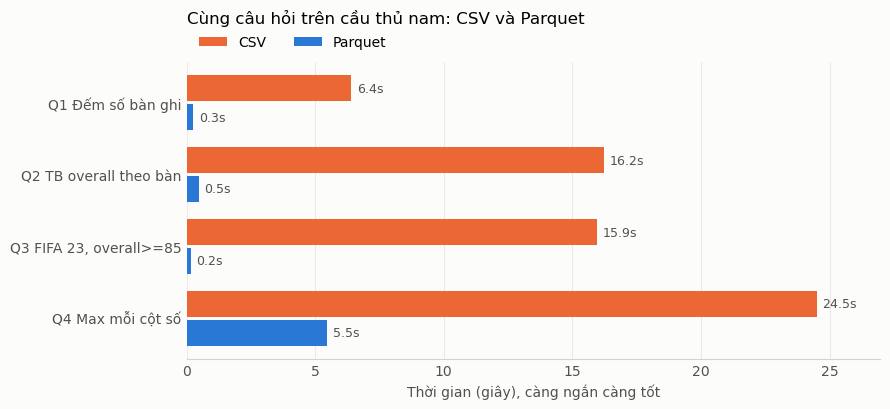

In [40]:
pv = bench.pivot(index="Câu_hỏi", columns="định dạng", values="giây")
pv["nhanh_gap"] = (pv["CSV"] / pv["Parquet"]).round(1)
display(pv)

COL = {"CSV": "#eb6834", "Parquet": "#2a78d6"}
fig, ax = plt.subplots(figsize=(9, 4.2), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
y = range(len(pv)); h = 0.36
for i, fmt in enumerate(["CSV", "Parquet"]):
    pos = [v + (i - 0.5) * (h + 0.04) for v in y]
    bars = ax.barh(pos, pv[fmt], height=h, color=COL[fmt], label=fmt)
    ax.bar_label(bars, labels=[f"{v:.1f}s" for v in pv[fmt]], padding=4, fontsize=9, color="#52514e")
ax.set_yticks(list(y), pv.index); ax.invert_yaxis()
ax.set_xlabel("Thời gian (giây), càng ngắn càng tốt", color="#52514e")
ax.set_title("Cùng câu hỏi trên cầu thủ nam: CSV và Parquet", loc="left", fontsize=12, pad=28)
for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color("#d4d3cd"); ax.tick_params(colors="#52514e", length=0)
ax.grid(axis="x", color="#ebeae5", linewidth=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2); ax.margins(x=0.1)
plt.tight_layout(); plt.savefig(f"{RESULTS}/variety_csv_vs_parquet.png", dpi=150); plt.show()

### Bằng chứng trong kế hoạch thực thi

Ô dưới in phần đọc dữ liệu trong kế hoạch Spark cho Q3. Với Parquet, cần chú ý ba dòng:
- `PartitionFilters`: lọc theo thư mục `fifa_version=23`, nên các thư mục khác không bị đọc.
- `PushedFilters`: điều kiện `overall >= 85` được đẩy xuống tận lúc đọc file.
- `ReadSchema`: chỉ đọc vài cột cần dùng.

In [41]:
import re
def scan_info(df):
    plan = df._jdf.queryExecution().executedPlan().toString()
    pat = r"(Format|PartitionFilters|PushedFilters|ReadSchema): (\[[^\]]*\]|struct<[^>]*>|\w+)"
    for line in plan.split("\n"):
        if "Scan" in line:
            for k, v in re.findall(pat, line):
                print(f"    {k}: {v[:150]}")
for fmt, df in [("CSV", csv_male), ("Parquet", pq_male)]:
    print(f"--- {fmt}")
    scan_info(df.where((F.col("fifa_version") == 23) & (F.col("overall") >= 85)).select("short_name", "club_name", "overall"))

--- CSV
    Format: CSV
    PartitionFilters: []
    ReadSchema: struct<fifa_version:int,short_name:string,overall:int,club_name:string>
--- Parquet
    Format: Parquet
    PartitionFilters: [isnotnull(fifa_version#12292), (fifa_version#12292 = 23)]
    PushedFilters: [IsNotNull(overall), GreaterThanOrEqual(overall,85)]
    ReadSchema: struct<short_name:string,overall:int,club_name:string>


## Phần 5 – Truy vấn trực tiếp trên kiểu mảng

Sau khi chuyển sang Parquet, `traits_arr` là **mảng thật**, nên có thể `explode` ra để đếm. Với CSV thì phải tách chuỗi lại mỗi lần đọc.

In [42]:
top_traits = (pq_players.where("fifa_version = 23")
              .select("gender", "player_id", F.explode("traits_arr").alias("trait"))
              # 1 cau thu xuat hien o nhieu ban cap nhat (fifa_update) -> dem cau thu KHONG trung
              .groupBy("gender", "trait").agg(F.countDistinct("player_id").alias("so_cau_thu"))
              .orderBy(F.desc("so_cau_thu")))
top_traits.where("gender = 'male'").show(10, truncate=False)

(pq_players.where("fifa_version = 23")
 .select(F.size("positions_arr").alias("số vị trí")).groupBy("số vị trí").count().orderBy("Số vị trí").show())

+------+-----------------------+----------+
|gender|trait                  |so_cau_thu|
+------+-----------------------+----------+
|male  |Technical Dribbler (AI)|1990      |
|male  |Long Shot Taker (AI)   |1768      |
|male  |Speed Dribbler (AI)    |1633      |
|male  |Flair                  |1509      |
|male  |Injury Prone           |1472      |
|male  |Long Passer (AI)       |1170      |
|male  |Playmaker (AI)         |1076      |
|male  |Dives Into Tackles (AI)|1067      |
|male  |Power Header           |924       |
|male  |Team Player            |916       |
+------+-----------------------+----------+
only showing top 10 rows

+---------+-----+
|số vị trí|count|
+---------+-----+
|        1|84453|
|        2|63136|
|        3|26510|
+---------+-----+



## Tổng kết cho báo cáo

Các file trong `notebooks/results/`:
- `variety_entities.csv`: 3 thực thể, số cột và số dòng của mỗi loại, phân theo kiểu dữ liệu.
- `variety_size.csv`: dung lượng CSV và Parquet (cả dung lượng thật trên đĩa, tức là ×3 bản sao).
- `variety_query_benchmark.csv` và `variety_csv_vs_parquet.png`: thời gian truy vấn.

Câu chốt gợi ý (điền số từ kết quả của bạn):
> *Dataset FIFA đa dạng ở 3 mức: (1) 3 loại thực thể với cấu trúc khác nhau, liên kết bằng khoá; (2) trường bán cấu trúc (danh sách, chỉ số "89+3", URL ảnh) nằm trong CSV; (3) cùng dữ liệu được lưu ở 2 định dạng. Chuyển sang Parquet giảm dung lượng ___ lần và tăng tốc truy vấn ___–___ lần, nhờ lưu theo cột, nén và bỏ qua phân vùng không cần đọc.*

Dữ liệu Parquet ở `/fifa/curated/` cũng là đầu vào cho giai đoạn 4 và notebook Velocity (`02_velocity_streaming.ipynb`).